# [LAB01] Đọc, kiểm tra và hiển thị ảnh

**Issue:** [LAB01] Read and display image  
**Branch:** `feature/lab01-read-display`  
**Notebook:** `lab_1/notebook/01_read_display.ipynb`  
**Source:** `lab_1/src/image_io.py`

## Mục tiêu
Xây dựng bước đầu tiên của pipeline xử lý ảnh:
1. Đọc ảnh bằng OpenCV (`cv2.imread`).
2. Kiểm tra ảnh có tồn tại / đọc được hay không.
3. Lấy thông tin ảnh: `shape`, height, width, số channel, `dtype`.
4. Hiển thị ảnh **đúng màu** (đổi BGR → RGB khi dùng Matplotlib).
5. Giải thích vì sao OpenCV mặc định dùng BGR.

## Các bước thực hiện
| Bước | Nội dung |
|---|---|
| 1 | Chọn ảnh màu rõ ràng, đặt vào `lab_1/data/input/` |
| 2 | Đọc ảnh bằng `cv2.imread()` |
| 3 | Kiểm tra trường hợp ảnh không đọc được |
| 4 | In shape, height, width, channels, dtype |
| 5 | Hiển thị ảnh |
| 6 | Đổi BGR → RGB trước khi dùng Matplotlib |
| 7 | Giải thích BGR |

## 0. Chuẩn bị môi trường
Import thư viện và module `image_io` do nhóm viết (nằm ở `lab_1/src/`). Tự xác định thư mục gốc `lab_1` từ thư mục chạy Jupyter, sau đó tạo đường dẫn tới `src/`, `data/input/` và `result/figures/`. Không phụ thuộc vào việc Jupyter được mở từ thư mục gốc hay thư mục `notebook`.

In [1]:
import sys
import importlib
from pathlib import Path
import tempfile

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Tim thu muc goc lab_1 tu thu muc dang chay Jupyter.
# Ho tro ca truong hop Jupyter chay tai lab_1/ hoac lab_1/notebook/.
current_dir = Path.cwd().resolve()
candidates = [current_dir, *current_dir.parents]
PROJECT_DIR = next(
    (p for p in candidates if (p / "src" / "image_io.py").is_file()),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Khong tim thay src/image_io.py. Hay mo dung thu muc lab_1 trong VS Code. "
        f"Thu muc dang chay: {current_dir}"
    )

SRC_DIR = PROJECT_DIR / "src"
# Dat src len dau de uu tien module cua nhom.
sys.path.insert(0, str(SRC_DIR))

# Neu image_io da duoc import tu file khac, bo module cu truoc khi import lai.
if "image_io" in sys.modules:
    old_module = sys.modules["image_io"]
    old_file = getattr(old_module, "__file__", None)
    if old_file is None or Path(old_file).resolve() != (SRC_DIR / "image_io.py").resolve():
        del sys.modules["image_io"]

import image_io
importlib.reload(image_io)

if not hasattr(image_io, "load_image"):
    raise AttributeError(
        "Da import file: " + str(image_io.__file__) +
        " nhung khong co ham load_image(). Hay kiem tra va luu file src/image_io.py."
    )

# Dung duong dan dua tren thu muc goc project, khong phu thuoc current working directory.
INPUT_DIR = PROJECT_DIR / "data" / "input"
FIG_DIR = PROJECT_DIR / "result" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_PATH = INPUT_DIR / "sample.jpg"
print("Thu muc project:", PROJECT_DIR)
print("Module image_io:", image_io.__file__)
print("Co load_image:", hasattr(image_io, "load_image"))
print("OpenCV version:", cv2.__version__)
print("Anh dau vao   :", IMAGE_PATH)


AttributeError: Da import file: C:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_1\src\image_io.py nhung khong co ham load_image(). Hay kiem tra va luu file src/image_io.py.

## Bước 1. Chọn ảnh màu rõ ràng và đặt vào `data/input/`

Ảnh đầu vào là `lab_1/data/input/sample.jpg`: ảnh màu có nhiều vùng màu rõ rệt (trời xanh, cỏ xanh lá, nhà đỏ, mặt trời vàng). Chọn ảnh như vậy giúp **nhìn thấy ngay khi màu bị sai** (ví dụ lỗi hoán đổi BGR/RGB sẽ làm trời chuyển sang màu cam).

> Bạn có thể thay bằng ảnh của riêng mình: chép vào `data/input/` và đặt tên `sample.jpg` (hoặc sửa `IMAGE_PATH`).

In [ ]:
# Kiểm tra thư mục input và liệt kê các file ảnh
print("Các file trong", INPUT_DIR, ":")
for p in sorted(INPUT_DIR.iterdir()):
    print(f"  {p.name:<20}{p.stat().st_size / 1024:>8.1f} KB")

Các file trong ../data/input :
  sample.jpg             139.5 KB


## Bước 2. Đọc ảnh bằng `cv2.imread()`

```python
image = cv2.imread(đường_dẫn, cờ_đọc)
```
- `đường_dẫn`: **chuỗi (str)** chỉ tới file ảnh.
- `cờ_đọc` (tuỳ chọn): `cv2.IMREAD_COLOR` (mặc định, ảnh màu 3 kênh), `cv2.IMREAD_GRAYSCALE` (ảnh xám), `cv2.IMREAD_UNCHANGED` (giữ nguyên, kể cả kênh alpha).
- Kết quả: **mảng NumPy** nếu thành công, hoặc **`None`** nếu thất bại.

In [ ]:
# Đọc ảnh bằng OpenCV (cv2.imread cần str nên chuyển Path -> str)
image = cv2.imread(str(IMAGE_PATH))

print("Kiểu của image:", type(image))

Kiểu của image: <class 'numpy.ndarray'>


## Bước 3. Kiểm tra trường hợp ảnh không đọc được

`cv2.imread()` **không ném lỗi** khi thất bại mà chỉ trả về `None`. Nếu không kiểm tra, lỗi sẽ xuất hiện ở các dòng code phía sau (ví dụ `'NoneType' object has no attribute 'shape'`) và rất khó tìm nguyên nhân. Vì vậy luôn phải kiểm tra `image is None`.

Các nguyên nhân thường gặp khiến `imread` trả về `None`:
- Sai đường dẫn hoặc sai tên file (đúng/sai chữ hoa chữ thường, thiếu đuôi file).
- File bị hỏng hoặc không phải ảnh (dù có đuôi `.jpg`).
- Định dạng ảnh không được OpenCV hỗ trợ.
- Thư mục chạy notebook khác với dự kiến nên đường dẫn tương đối sai.

In [ ]:
# Kiểm tra theo cách của khung định hướng: nếu image là None thì báo lỗi
if image is None:
    print("Không đọc được ảnh:", IMAGE_PATH)
else:
    print("Đọc ảnh thành công:", IMAGE_PATH)

Đọc ảnh thành công: ../data/input/sample.jpg


### Minh hoạ cho các trường hợp lỗi

Ta thử hai tình huống lỗi: (a) file **không tồn tại**, (b) file **có đuôi `.jpg` nhưng thực chất không phải ảnh**. Sau đó dùng hàm `image_io.load_image()` (có kiểm tra lỗi, báo rõ nguyên nhân).

In [ ]:
# (a) File không tồn tại -> imread trả về None (KHÔNG báo lỗi)
bad_path = INPUT_DIR / "khong_ton_tai.jpg"
img_a = cv2.imread(str(bad_path))
print("(a) File không tồn tại   -> imread trả về:", img_a)

# (b) File có đuôi .jpg nhưng nội dung là văn bản -> cũng trả về None
with tempfile.TemporaryDirectory() as tmp:
    fake = Path(tmp) / "fake.jpg"
    fake.write_text("day khong phai la anh")
    img_b = cv2.imread(str(fake))
    print("(b) File hỏng/không phải ảnh -> imread trả về:", img_b)

    # Dùng hàm load_image của nhóm: báo lỗi RÕ RÀNG, phân biệt hai nguyên nhân
    for p in (bad_path, fake):
        try:
            image_io.load_image(p)
        except (FileNotFoundError, ValueError) as e:
            print(f"load_image báo {type(e).__name__}: {e}")

(a) File không tồn tại   -> imread trả về: None
(b) File hỏng/không phải ảnh -> imread trả về: None
load_image báo FileNotFoundError: Không tìm thấy file ảnh: ../data/input/khong_ton_tai.jpg
load_image báo ValueError: OpenCV không đọc được ảnh (file hỏng hoặc sai định dạng): /tmp/tmp_1x5rci_/fake.jpg


[ WARN:0@0.537] global loadsave.cpp:278 findDecoder imread_('../data/input/khong_ton_tai.jpg'): can't open/read file: check file path/integrity


**Nhận xét:** hàm `load_image` giúp *dừng sớm và báo lỗi rõ nguyên nhân* thay vì để chương trình chạy tiếp với `None`.

## Bước 4. In shape, height, width, số channel và dtype

Ảnh số được biểu diễn là **một lưới (ma trận) các pixel**. Với ảnh màu, mỗi pixel là một bộ **3 giá trị** (3 kênh màu). Trong NumPy:

```
image.shape = (height, width, channels)
```
- **height**: số **hàng** pixel (chiều cao).
- **width**: số **cột** pixel (chiều rộng).
- **channels**: số kênh màu (3 với ảnh màu, 1 với ảnh xám).
- Thứ tự là **hàng trước, cột sau** → `height` đứng trước `width` (ngược với thói quen "rộng × cao").
- **`dtype = uint8`**: mỗi giá trị là số nguyên 8-bit không dấu, nằm trong khoảng `0–255`.

In [ ]:
if image is None:
    raise SystemExit("Không đọc được ảnh -> dừng.")

print("Shape   :", image.shape)
print("Height  :", image.shape[0], " (số hàng)")
print("Width   :", image.shape[1], " (số cột)")
print("Channels:", image.shape[2], " (B, G, R)")
print("Dtype   :", image.dtype, "  (số nguyên 8-bit không dấu: 0..255)")
print("Tổng số phần tử:", image.size, "= height x width x channels =",
      image.shape[0], "x", image.shape[1], "x", image.shape[2])

Shape   : (600, 800, 3)
Height  : 600  (số hàng)
Width   : 800  (số cột)
Channels: 3  (B, G, R)
Dtype   : uint8   (số nguyên 8-bit không dấu: 0..255)
Tổng số phần tử: 1440000 = height x width x channels = 600 x 800 x 3


In [ ]:
# Cách dùng hàm của nhóm: gói thông tin ảnh trong dict rồi in ra
info = image_io.get_image_info(image)
image_io.print_image_info(info)

Shape (H, W, C)  : (600, 800, 3)
Height (chiều cao): 600 pixel (số hàng)
Width  (chiều rộng): 800 pixel (số cột)
Channels (số kênh): 3
Dtype (kiểu dữ liệu): uint8
Giá trị pixel nhỏ nhất / lớn nhất: 0 / 255
Tổng số pixel (H x W): 480000


### Quan sát pixel: ảnh thực chất là ma trận số

Mỗi pixel `image[y, x]` là một mảng 3 phần tử theo thứ tự **[B, G, R]**. Dưới đây in giá trị một vùng nhỏ và phóng to vùng đó để thấy từng pixel.

Pixel ở góc trên-trái image[0, 0]  : [194 159  61] -> [B, G, R]
Pixel thân nhà image[400, 300]      : B=59, G=61, R=199  -> R lớn nhất => màu đỏ

Vùng 3x3 pixel đầu tiên (mỗi pixel là [B, G, R]):
[[[194 159  61]
  [191 156  58]
  [198 163  65]]

 [[195 160  62]
  [191 156  58]
  [192 157  59]]

 [[190 155  57]
  [193 158  60]
  [199 162  64]]]


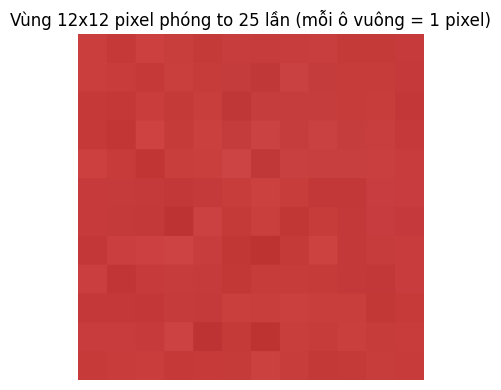

In [ ]:
# Pixel đơn lẻ: image[y, x] -> [B, G, R]   (y = hàng, x = cột)
print("Pixel ở góc trên-trái image[0, 0]  :", image[0, 0], "-> [B, G, R]")

# Pixel nằm ở thân nhà (màu đỏ): kênh R phải lớn nhất
y, x = 400, 300
b, g, r = image[y, x]
print(f"Pixel thân nhà image[{y}, {x}]      : B={b}, G={g}, R={r}  -> R lớn nhất => màu đỏ")

# Ma trận 3x3 pixel đầu tiên
print("\nVùng 3x3 pixel đầu tiên (mỗi pixel là [B, G, R]):")
print(image[0:3, 0:3])

# Phóng to một vùng 12x12 pixel (INTER_NEAREST giữ nguyên các ô vuông pixel)
patch = image[395:407, 295:307]
zoom = cv2.resize(patch, None, fx=25, fy=25, interpolation=cv2.INTER_NEAREST)
image_io.show_image(zoom, title="Vùng 12x12 pixel phóng to 25 lần (mỗi ô vuông = 1 pixel)",
                    figsize=(4, 4), save_path=FIG_DIR / "01_pixel_zoom.png")

## Bước 5 & 6. Hiển thị ảnh và đổi BGR → RGB khi dùng Matplotlib

Có hai cách hiển thị:

1. **`cv2.imshow()`**: mở cửa sổ riêng, nhận trực tiếp ảnh **BGR**. Chỉ chạy được khi có màn hình (không dùng được trên Colab/server).
2. **Matplotlib `plt.imshow()`**: hiển thị ngay trong notebook, nhưng **hiểu 3 kênh theo thứ tự RGB** → phải đổi BGR → RGB trước.

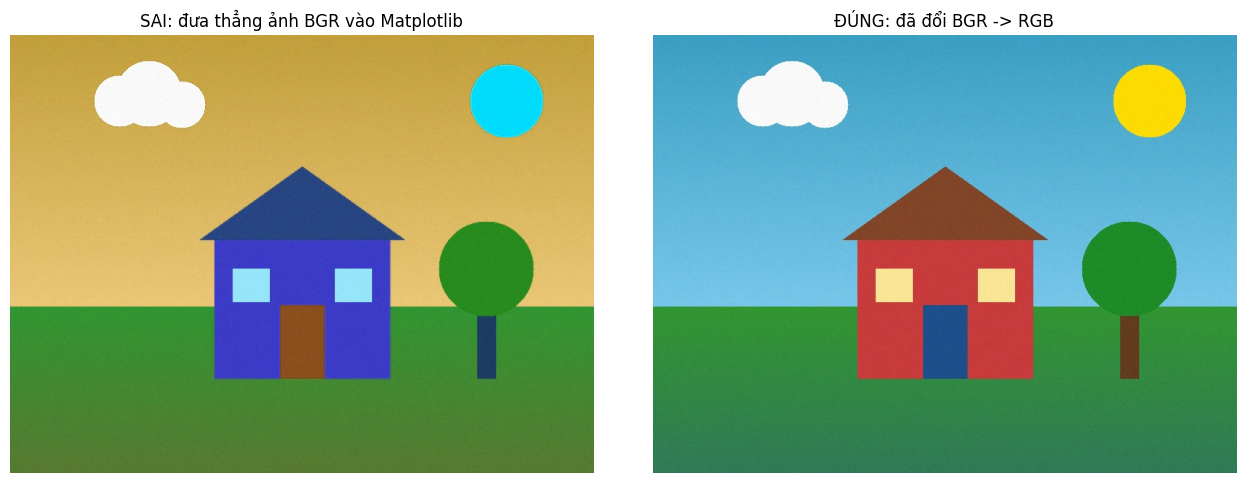

In [ ]:
# Đổi BGR -> RGB bằng cv2.cvtColor
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# So sánh: đưa thẳng BGR vào Matplotlib (SAI) và ảnh đã đổi sang RGB (ĐÚNG)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].imshow(image)                 # SAI: Matplotlib coi kênh đầu tiên (B) là R
axes[0].set_title("SAI: đưa thẳng ảnh BGR vào Matplotlib")
axes[0].axis("off")

axes[1].imshow(image_rgb)             # ĐÚNG: đã đổi sang RGB
axes[1].set_title("ĐÚNG: đã đổi BGR -> RGB")
axes[1].axis("off")

plt.tight_layout()
fig.savefig(FIG_DIR / "01_bgr_vs_rgb.png", dpi=120, bbox_inches="tight")
plt.show()

**Nhận xét:** ở hình bên trái, kênh Xanh dương (B) và Đỏ (R) bị hoán đổi nên **bầu trời xanh trở thành màu cam/vàng, nhà đỏ trở thành xanh dương, mặt trời vàng chuyển sang cyan**. Hình bên phải hiển thị đúng màu thật.

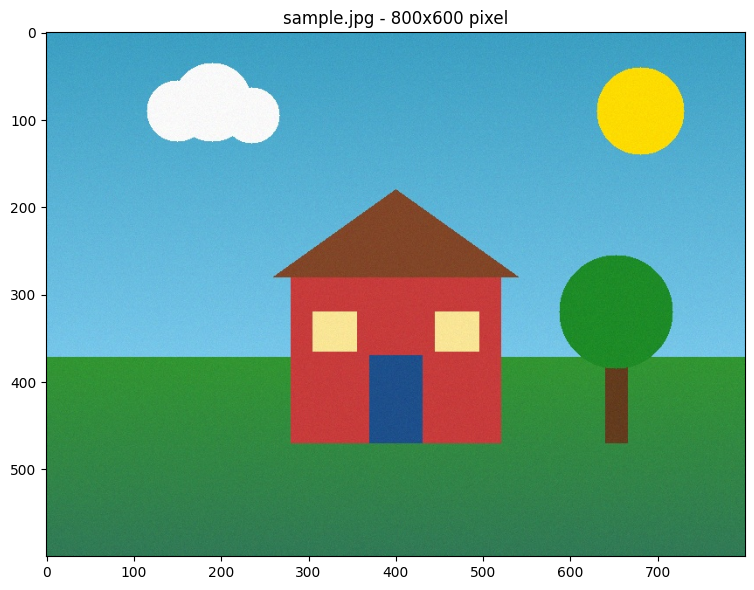

In [ ]:
# Hiển thị ảnh đúng màu bằng hàm của nhóm (tự đổi BGR -> RGB bên trong)
image_io.show_image(image, title=f"sample.jpg - {image.shape[1]}x{image.shape[0]} pixel",
                    axis=True, figsize=(8, 6), save_path=FIG_DIR / "01_display_image.png")

In [ ]:
# (Tuỳ chọn) Hiển thị bằng cửa sổ OpenCV - nhận ảnh BGR trực tiếp, KHÔNG cần đổi màu.
# Chỉ đặt True khi chạy trên máy có màn hình; trên Colab/server có thể làm sập kernel.
USE_IMSHOW = False

if USE_IMSHOW:
    cv2.imshow("sample.jpg (OpenCV)", image)
    cv2.waitKey(0)            # chờ nhấn phím bất kỳ
    cv2.destroyAllWindows()
else:
    print("Bỏ qua cv2.imshow (USE_IMSHOW = False). Đã hiển thị bằng Matplotlib ở trên.")

Bỏ qua cv2.imshow (USE_IMSHOW = False). Đã hiển thị bằng Matplotlib ở trên.


## Bước 7. Giải thích vì sao OpenCV mặc định dùng BGR

- **OpenCV** đọc ảnh màu theo thứ tự kênh **B – G – R** (Blue, Green, Red), tức `image[y, x] = [B, G, R]`.
- **Matplotlib** (cũng như Pillow và hầu hết thư viện hiển thị hiện đại) dùng thứ tự **R – G – B**.

**Lý do OpenCV dùng BGR** là *quy ước lịch sử*: khi OpenCV được phát triển, nhiều camera, driver và định dạng ảnh phổ biến lúc đó (ví dụ BMP trên Windows) lưu pixel theo thứ tự BGR. OpenCV chọn thứ tự này để tương thích với phần cứng/phần mềm thời đó, rồi giữ nguyên đến nay để **không làm hỏng code cũ**. Đây không phải vì BGR tốt hơn RGB về mặt kỹ thuật.

**Hậu quả khi quên đổi:** màu bị sai vì kênh B và R bị hoán đổi. Quy tắc nhớ:

> *Ảnh từ OpenCV = BGR → trước khi đưa vào Matplotlib, luôn đổi sang RGB bằng `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`.*

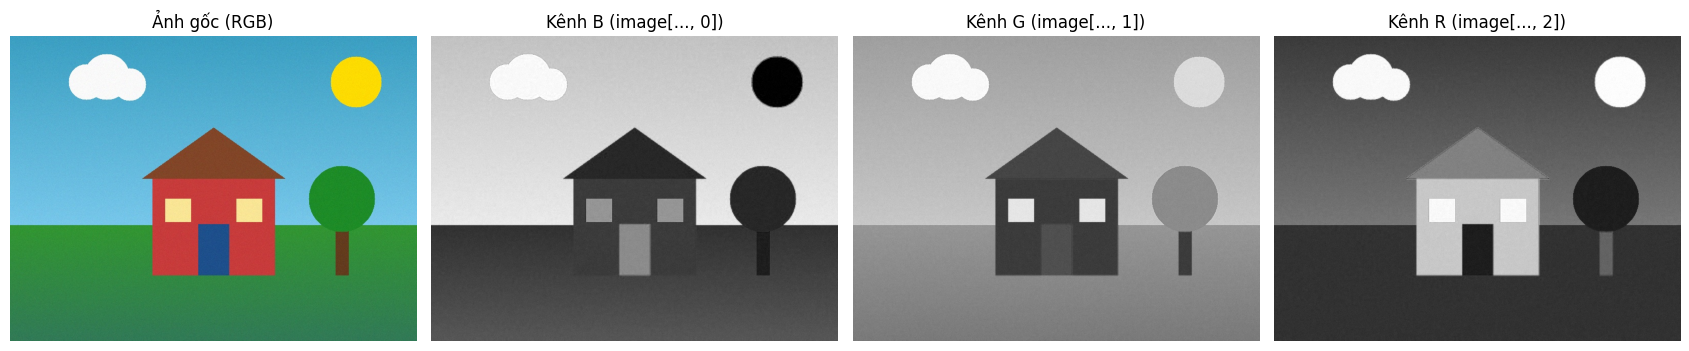

In [ ]:
# Minh hoạ: tách 3 kênh B, G, R và hiển thị từng kênh bằng ảnh xám
B, G, R = cv2.split(image)       # cv2.split trả về đúng thứ tự B, G, R (cũng có thể dùng image[..., 0], [..., 1], [..., 2])

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].imshow(image_rgb);                  axes[0].set_title("Ảnh gốc (RGB)")
axes[1].imshow(B, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Kênh B (image[..., 0])")
axes[2].imshow(G, cmap="gray", vmin=0, vmax=255); axes[2].set_title("Kênh G (image[..., 1])")
axes[3].imshow(R, cmap="gray", vmin=0, vmax=255); axes[3].set_title("Kênh R (image[..., 2])")
for ax in axes: ax.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "01_bgr_channels.png", dpi=120, bbox_inches="tight")
plt.show()

**Đọc hình trên:** kênh càng sáng nghĩa là pixel đó chứa càng nhiều màu tương ứng.
- Vùng **bầu trời** sáng nhất ở kênh **B**.
- Vùng **cỏ, tán cây** sáng nhất ở kênh **G**.
- **Thân nhà đỏ** và **mặt trời vàng** sáng ở kênh **R** (mặt trời vàng = R + G cao, B thấp).

In [ ]:
# Kiểm chứng bằng số: pixel thân nhà (màu đỏ) có kênh R lớn nhất,
# và đảo BGR <-> RGB bằng cách đảo thứ tự kênh cho cùng kết quả với cv2.cvtColor
manual_rgb = image[..., ::-1]               # đảo trục kênh: [B,G,R] -> [R,G,B]
print("Đảo kênh thủ công == cv2.cvtColor ?", np.array_equal(manual_rgb, image_rgb))
print("Pixel thân nhà ở dạng BGR :", image[400, 300])
print("Pixel thân nhà ở dạng RGB :", image_rgb[400, 300])

Đảo kênh thủ công == cv2.cvtColor ? True
Pixel thân nhà ở dạng BGR : [ 59  61 199]
Pixel thân nhà ở dạng RGB : [199  61  59]


## Tổng kết

| Yêu cầu | Trạng thái |
|---|---|
| Ảnh đầu vào trong `data/input` | ✅ `data/input/sample.jpg` |
| Notebook đọc được ảnh | ✅ `cv2.imread` / `image_io.load_image` |
| Có kiểm tra lỗi | ✅ kiểm tra `None`, file không tồn tại, file hỏng |
| Có thông tin kích thước/channel | ✅ shape, height, width, channels, dtype |
| Ảnh hiển thị đúng màu | ✅ đổi BGR → RGB trước khi dùng Matplotlib |
| Có giải thích BGR/RGB | ✅ phần Bước 7 + hình so sánh + tách kênh |

**Kiến thức rút ra**
- Ảnh số là ma trận các pixel; ảnh màu có `shape = (height, width, channels)`.
- `cv2.imread()` đọc ảnh theo **BGR** và trả về `None` khi lỗi (không ném exception).
- Matplotlib hiển thị theo **RGB** → phải `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`.
- Dùng đường dẫn tương đối để người khác clone repo vẫn chạy được.

**Commit gợi ý:** `feat: implement image reading and display`